In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [3]:
data = pd.read_csv("../Customer-Segmentation/rfm data/rfm.csv")
df=pd.DataFrame(data)
df.head()

,Customer Id,Recency,Frequency,Monetary,Avg_Order_Value,Unique_Product_Categories,Avg_Discount_Rate,Total_Profit
0,1,793,1,499.950012,499.950012,1,0.060,159.690002
1,2,137,4,1819.730034,454.932508,3,0.126,208.739999
2,3,230,5,3537.680094,707.536019,4,0.105,334.489999
3,4,381,4,1719.630030,429.907507,4,0.135,-439.979992
4,5,458,3,1274.750023,424.916674,3,0.140,309.850002


In [4]:
model_features = ["Recency","Frequency","Monetary","Avg_Discount_Rate","Unique_Product_Categories","Total_Profit"]
X = df[model_features].dropna().copy()

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)

(20652, 6)


In [6]:
inertia = []
k_values = range(2, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

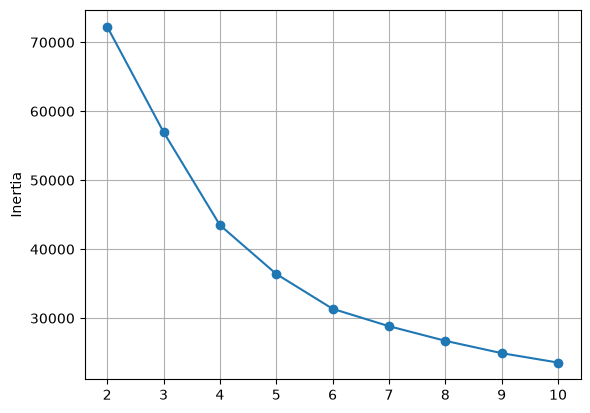

In [7]:
plt.plot(k_values, inertia, marker="o")
plt.xticks(k_values)
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

In [8]:
kmeans_5 = KMeans(n_clusters=5,random_state=42,n_init=10)
clusters_5 = kmeans_5.fit_predict(X_scaled)

In [9]:
X_5 = X.copy()
X_5["Cluster"] = clusters_5
print(X_5.head())

   Recency  Frequency     Monetary  Avg_Discount_Rate  \
0      793          1   499.950012              0.060   
1      137          4  1819.730034              0.126   
2      230          5  3537.680094              0.105   
3      381          4  1719.630030              0.135   
4      458          3  1274.750023              0.140   

   Unique_Product_Categories  Total_Profit  Cluster  
0                          1    159.690002        3  
1                          3    208.739999        0  
2                          4    334.489999        0  
3                          4   -439.979992        0  
4                          3    309.850002        3  


In [10]:
cluster_percentage = (X_5["Cluster"].value_counts(normalize=True).sort_index().mul(100))
print(cluster_percentage.round(2))

Cluster
0    27.19
1    18.77
2    19.47
3    11.38
4    23.18
Name: proportion, dtype: float64


In [11]:
cluster_profile = (X_5.groupby("Cluster").mean().round(2))
print(cluster_profile)

         Recency  Frequency  Monetary  Avg_Discount_Rate  \
Cluster                                                    
0         260.48       4.30   2443.32               0.10   
1          69.36       1.03    314.16               0.17   
2         251.04       6.60   4198.20               0.10   
3         638.07       2.61   1476.35               0.10   
4          67.86       1.02    312.37               0.05   

         Unique_Product_Categories  Total_Profit  
Cluster                                           
0                             4.15         77.53  
1                             1.05         31.97  
2                             4.72        700.23  
3                             3.29        176.20  
4                             1.04         37.12  


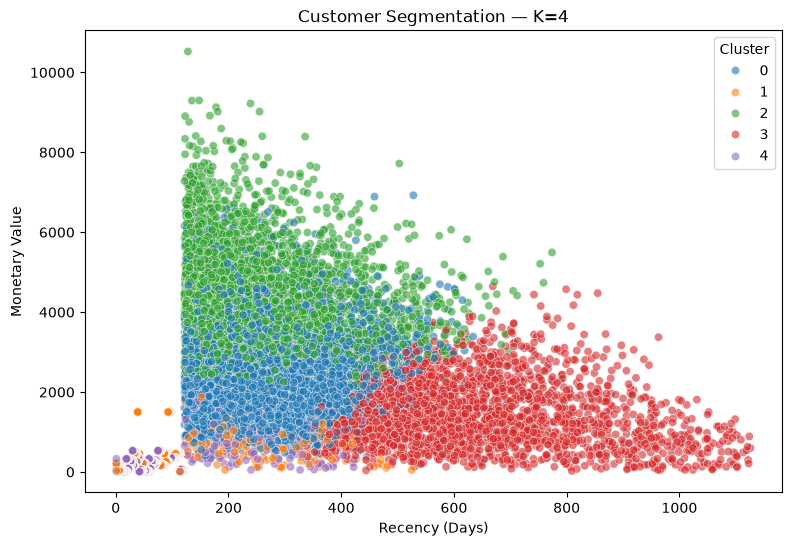

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=X_5,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.6
)

plt.title("Customer Segmentation — K=4")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value")

plt.show()

In [13]:
X_model = pd.DataFrame(
    X_scaled,
    columns=model_features,
    index=X.index
)

print("Standardized features:", X_model.shape)
print(X_model.head())

Standardized features: (20652, 6)
    Recency  Frequency  Monetary  Avg_Discount_Rate  \
0  2.868294  -0.898450 -0.763865          -0.864304   
1 -0.421731   0.335793  0.022989           0.503427   
2  0.044690   0.747207  1.047232           0.068240   
3  0.801998   0.335793 -0.036691           0.689936   
4  1.188175  -0.075621 -0.301928           0.793552   

   Unique_Product_Categories  Total_Profit  
0                  -1.075012     -0.083247  
1                   0.081268      0.042806  
2                   0.659407      0.365970  
3                   0.659407     -1.624332  
4                   0.081268      0.302648  


In [14]:
X = X_model.copy()
y = X_5["Cluster"].astype(int).copy()

print("Training features:", X.shape)
print("Target distribution:")
print(y.value_counts().sort_index())

Training features: (20652, 6)
Target distribution:
Cluster
0    5615
1    3877
2    4021
3    2351
4    4788
Name: count, dtype: int64


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16521, 6)
Testing data: (4131, 6)


In [16]:
rf_model = RandomForestClassifier(n_estimators=200,random_state=42)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [17]:
y_pred_rf = rf_model.predict(X_test)

In [18]:
accuracy = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", accuracy)

Random Forest Accuracy: 0.9840232389251997


In [19]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.97      0.98      0.97      1123
           1       1.00      0.99      1.00       776
           2       0.98      0.98      0.98       804
           3       0.96      0.97      0.97       470
           4       1.00      0.99      0.99       958

    accuracy                           0.98      4131
   macro avg       0.98      0.98      0.98      4131
weighted avg       0.98      0.98      0.98      4131



In [20]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)

Avg_Discount_Rate            0.267794
Recency                      0.226399
Total_Profit                 0.154389
Frequency                    0.120864
Monetary                     0.117822
Unique_Product_Categories    0.112731
dtype: float64


In [21]:

import joblib
import os

# Save the trained models and preprocessing object
joblib.dump(rf_model, "backend/models/random_forest.pkl")
joblib.dump(scaler, "backend/models/scaler.pkl")
joblib.dump(kmeans_5, "backend/models/kmeans.pkl")

# Save the exact feature order
joblib.dump(model_features, "backend/models/model_features.pkl")

['backend/models/model_features.pkl']